# Drone flight planner, advanced: image coverage, terrain following, wind and batteries

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/flight_planner_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [Drone flight planner](https://openskylab.space/edu_viz_flight_planner.html) · [česká verze](flight_planner_pro_cs.ipynb)

The advanced version of the flight planning notebook. On the wooded slope of the Vltava valley at Roztoky you compare three ways of holding height: constant above the take-off point, following the terrain from DMR 5G, and following the canopy surface from DMP 1G. For each you compute how many images see every point, the clearance above the trees and how fast the drone would have to climb. Then you choose the line direction from today's wind forecast and split the mission into flights of one battery each.

**Goal:** compute image coverage of the area and clearance above the surface for three height modes, find the smoothing of the height profile needed for the climb rate, find the fastest line direction in real wind, and split the mission into flights so that energy remains for every return.

**Data:** DMR 5G (terrain) and DMP 1G (surface including vegetation and buildings) from ČÚZK, ImageServer services, 2 m cells, a 1.2 × 0.8 km area on the left slope of the Vltava valley at Roztoky; today's hourly wind forecast at 80 m from Open-Meteo; drone and camera parameters of the Mavic 3E from the manufacturer's data sheet. DMP 1G comes from airborne laser scanning in 2009–2013, so trees may have grown or been felled since. The coverage model assumes a camera pointing straight down and ignores occlusion (a crown hides the ground beneath it); the turn time is indicative.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 60 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.

In [2]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from scipy.ndimage import maximum_filter, uniform_filter1d

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Window of a ČÚZK raster (dmr5g, dmp1g, dmp_obrazova_korelace) in S-JTSK (EPSG:5514), heights in Bpv.
    Returns the height array (row 0 = north) and its transform."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

## 2. Terrain, surface and the line plan

DMR 5G describes the bare terrain, DMP 1G the surface the camera sees: tree crowns and roofs. Their difference is the height of vegetation and buildings. The plan is the same as in the basic version: a Mavic 3E camera, east–west lines, take-off at the western edge.

terrain 175–257 m a.s.l., surface 175–276 m a.s.l., take-off 225 m a.s.l.
vegetation or buildings taller than 2 m on 83% of the area, median height 14.4 m, 99th percentile 26.2 m


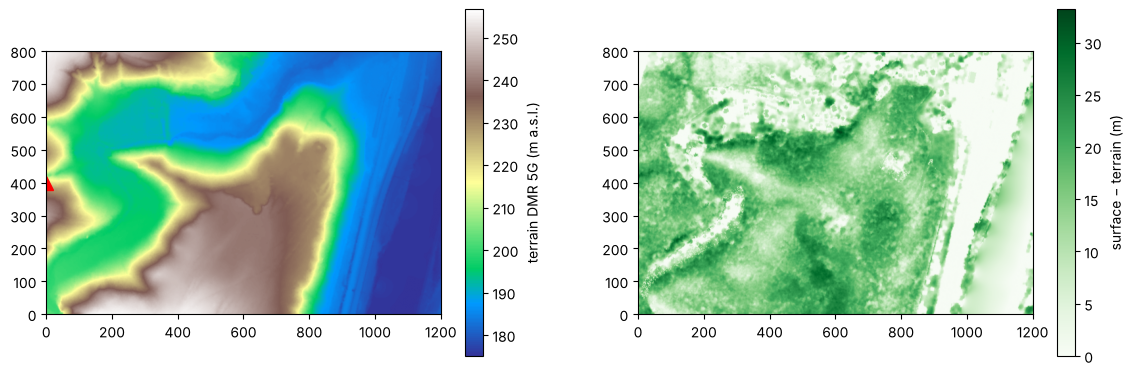

In [3]:
LON, LAT = 14.392, 50.152            # ◀ parameter: centre of the area (left slope of the Vltava valley at Roztoky)
W, Hh, RES = 1200, 800, 2.0          # width (E–W) and height (N–S) of the area in m, 2 m cells
cx, cy = Transformer.from_crs(4326, 5514, always_xy=True).transform(LON, LAT)
box = (cx - W / 2, cy - Hh / 2, cx + W / 2, cy + Hh / 2)
dmr, _ = cuzk_raster("dmr5g", *box, res=RES)       # terrain
dmp, _ = cuzk_raster("dmp1g", *box, res=RES)       # surface including trees and buildings
veg = np.clip(dmp - dmr, 0, None)                   # height of vegetation and buildings above the terrain
z_takeoff = float(np.median(dmr[:, :10]))           # take-off point at the western edge
HOME = (0.0, Hh / 2)                                # ◀ parameter: position of the take-off point in the area (x, y in m)
xs = np.arange(dmr.shape[1]) * RES + RES / 2        # coordinates of cell centres (x east, y north)
ys = Hh - np.arange(dmr.shape[0]) * RES - RES / 2
print(f"terrain {dmr.min():.0f}–{dmr.max():.0f} m a.s.l., surface {dmp.min():.0f}–{dmp.max():.0f} m a.s.l., take-off {z_takeoff:.0f} m a.s.l.")
print(f"vegetation or buildings taller than 2 m on {np.mean(veg > 2):.0%} of the area, median height {np.median(veg[veg > 2]):.1f} m, 99th percentile {np.percentile(veg, 99):.1f} m")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, arr, lbl, cm in [(ax[0], dmr, "terrain DMR 5G (m a.s.l.)", "terrain"), (ax[1], veg, "surface − terrain (m)", "Greens")]:
    im = a.imshow(arr, cmap=cm, extent=(0, W, 0, Hh)); fig.colorbar(im, ax=a, label=lbl)
ax[0].plot(*HOME, "r^", ms=10); plt.show()

In [4]:
CAM = dict(sw=17.3, sh=13.0, pw=5280, ph=3956, f=12.3)   # Mavic 3E: sensor (mm), pixels, focal length (mm)
H0 = 80.0             # ◀ parameter: flight height (m) above the take-off point, the terrain or the surface depending on the mode
FO, SO = 0.80, 0.70   # ◀ parameter: forward and side overlap
V = 8.0               # ◀ parameter: airspeed (m/s)
SMOOTH = 40           # ◀ parameter: smoothing length of the line height profile (m) for terrain and surface following
p, f = CAM["sw"] / CAM["pw"] / 1000, CAM["f"] / 1000
gsd0 = H0 * p / f
base = (1 - FO) * CAM["ph"] * gsd0                  # distance between shots along the line (short side of the image along)
spacing = (1 - SO) * CAM["pw"] * gsd0               # line spacing (long side across)
line_y = np.arange(0, Hh + spacing / 2, spacing)    # E–W lines
shot_x = np.arange(0, W + base / 2, base)
xline = np.arange(0, W + RES / 2, RES)

def sample(arr, x, y):
    i = np.clip(((Hh - y) / RES).astype(int), 0, arr.shape[0] - 1)
    j = np.clip((x / RES).astype(int), 0, arr.shape[1] - 1)
    return arr[i, j]

def altitude(mode, y, smooth=SMOOTH):
    """Altitude of the drone along line y at the points xline."""
    if mode == "constant":
        return np.full_like(xline, z_takeoff + H0)
    ref = sample(dmr if mode == "terrain" else dmp, xline, np.full_like(xline, y))
    n = max(int(smooth / RES), 1)
    if n > 1:                                         # maximum first (so the drone does not undercut a peak), then the mean
        ref = uniform_filter1d(maximum_filter(ref, size=n, mode="nearest"), size=n, mode="nearest")
    return ref + H0

print(f"GSD at {H0:.0f} m: {gsd0 * 100:.2f} cm/px, base {base:.1f} m, line spacing {spacing:.1f} m, {len(line_y)} lines × {len(shot_x)} shots")
print(f"in theory on flat ground: every point on {1 / ((1 - FO) * (1 - SO)):.1f} images")

GSD at 80 m: 2.13 cm/px, base 16.9 m, line spacing 33.8 m, 25 lines × 72 shots
in theory on flat ground: every point on 16.7 images


## 3. How many images see every point

For each image we compute which surface cells lie in its footprint. The footprint grows with the camera height above what it sees, so crowns closer to the camera are covered by a smaller patch. We compare three modes: **constant** height H0 above the take-off point, **terrain** (H0 above DMR 5G) and **surface** (H0 above DMP 1G). For following, the height profile of the line is smoothed (`SMOOTH`).

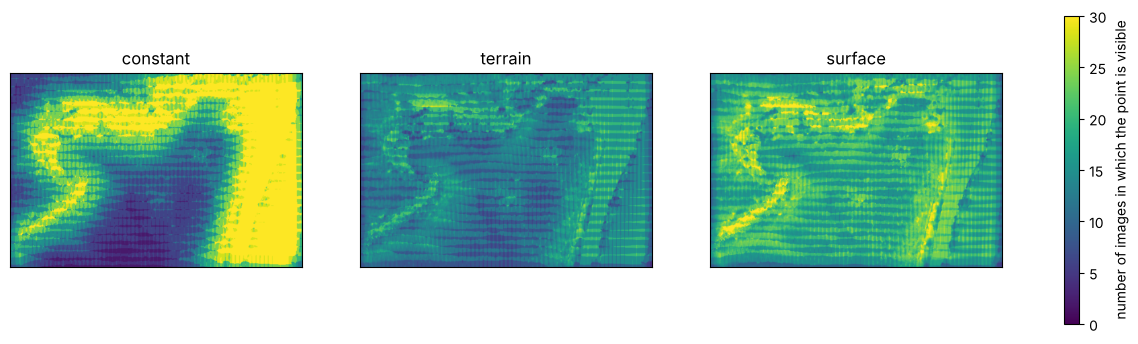

,median images per point,share of points on < 9 images,GSD on the surface 5 % (cm),GSD on the surface 95 % (cm),smallest clearance above the surface (m)
constant,20.0,0.21,1.09,3.34,29.13
terrain,13.0,0.10,1.55,2.18,51.83
surface,20.0,0.00,2.14,2.46,79.54


In [5]:
MODES = ["constant", "terrain", "surface"]   # constant height above take-off, following DMR 5G, following DMP 1G
hx, hy = CAM["sh"] / CAM["f"] / 2, CAM["sw"] / CAM["f"] / 2   # half footprint per 1 m of height: along the line (x), across (y)
cov, rows = {}, {}
for mode in MODES:
    cnt = np.zeros(dmr.shape, dtype=np.int16)
    agl_all, clear = [], np.inf
    for y in line_y:
        zl = altitude(mode, y)
        surf = sample(dmp, xline, np.full_like(xline, y))
        agl_all.append(zl - surf); clear = min(clear, float((zl - surf).min()))
        for x in shot_x:
            zc = float(np.interp(x, xline, zl))
            ext = zc - dmp.min()
            i0, i1 = int(max((Hh - y - ext * hy) / RES, 0)), int(min((Hh - y + ext * hy) / RES + 1, dmr.shape[0]))
            j0, j1 = int(max((x - ext * hx) / RES, 0)), int(min((x + ext * hx) / RES + 1, dmr.shape[1]))
            h = zc - dmp[i0:i1, j0:j1]                 # camera height above the surface it sees
            cnt[i0:i1, j0:j1] += (np.abs(xs[j0:j1][None, :] - x) <= h * hx) & (np.abs(ys[i0:i1][:, None] - y) <= h * hy) & (h > 0)
    cov[mode] = cnt
    inner = cnt[20:-20, 20:-20]                        # without the 40 m edge strip
    agl_all = np.concatenate(agl_all)
    rows[mode] = {"median images per point": np.median(inner), "share of points on < 9 images": np.mean(inner < 9),
                  "GSD on the surface 5 % (cm)": np.percentile(agl_all, 5) * p / f * 100, "GSD on the surface 95 % (cm)": np.percentile(agl_all, 95) * p / f * 100,
                  "smallest clearance above the surface (m)": clear}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, mode in zip(ax, MODES):
    im = a.imshow(cov[mode], cmap="viridis", vmin=0, vmax=30, extent=(0, W, 0, Hh)); a.set_title(mode); a.set_xticks([]); a.set_yticks([])
fig.colorbar(im, ax=ax, label="number of images in which the point is visible"); plt.show()
pd.DataFrame(rows).T.round(2)

> **✏️ Task 1.** On flat ground every point would be on as many images as the plan cell printed. Why is the median lower for terrain following and higher for constant height and surface following? Where in the constant-height map are the points with the fewest images, and why? Forest photogrammetry usually calls for higher overlap: change `FO` and `SO` and watch the share of points on fewer than 9 images.

*Your answer:* 

> **✏️ Task 2.** Look at the smallest clearance above the surface and the range of GSD. Why is the clearance above the tallest crowns smallest and GSD most variable at constant height? What would happen with terrain following if the trees had grown 5 m since the 2009–2013 scanning, or if there were a mast in the area that the DMP did not capture? Set `H0 = 50` and compare.

*Your answer:* 

## 4. How fast the drone would have to climb

When following terrain or surface, the drone flies at speed V and its height follows the line profile. The vertical speed is V times the slope of the profile. When it exceeds the climb or descent limit, the drone has to slow down. The table shows different smoothing lengths: 2 m means no smoothing.

In [6]:
V_UP, V_DOWN = 6.0, 6.0      # ◀ parameter: maximum climb and descent rate (m/s), Mavic 3E in normal mode
rows = {}
for mode in ["terrain", "surface"]:
    for sm in [2, 20, 60, 100]:
        vz = np.concatenate([np.diff(altitude(mode, y, sm)[::d]) / RES * V for y in line_y for d in (1, -1)])
        top = V * min(V_UP / vz.max(), V_DOWN / -vz.min(), 1.0)
        dev = np.concatenate([altitude(mode, y, sm) - altitude(mode, y, 2) for y in line_y])
        rows[(mode, sm)] = {"largest climb rate (m/s)": vz.max(), "share of segments over the limit": np.mean((vz > V_UP) | (vz < -V_DOWN)),
                            "speed to keep up (m/s)": top, "drone higher than H0 by (m, median)": np.median(dev), "max (m)": dev.max()}
pd.DataFrame(rows).T.round(2)

largest climb rate (m/s)  share of segments over the limit  \
terrain 2                       22.53                              0.01   
        20                       9.62                              0.00   
        60                       5.65                              0.00   
        100                      4.14                              0.00   
surface 2                       57.37                              0.17   
        20                      10.12                              0.02   
        60                       4.93                              0.00   
        100                      4.04                              0.00   

             speed to keep up (m/s)  drone higher than H0 by (m, median)  \
terrain 2                      2.13                                 0.00   
        20                     4.99                                 0.66   
        60                     8.00                                 1.98   
        100                    8.00                                 3.38   
surface 2                      0.84                                 0.00   
        20                     4.74                                 2.03   
        60                     8.00                                 5.27   
        100                    8.00                                 7.82   

             max (m)  
terrain 2       0.00  
        20     11.70  
        60     25.89  
        100    34.86  
surface 2       0.00  
        20     22.37  
        60     27.08  
        100    33.97

> **✏️ Task 3.** Why is the surface profile much steeper than the terrain profile, although the lines are the same? What is the shortest smoothing length that lets the drone keep within the 6 m/s limit at 8 m/s, and what do you lose (the columns showing how much higher than H0 it flies)? How would the result change at 12 m/s?

*Your answer:* 

## 5. Wind and line direction

The drone keeps airspeed V. On a downwind line the ground speed increases, upwind it decreases, and in a crosswind the drone has to crab, so it decreases in both directions. We compute the time of the whole mission for line azimuths from 0° to 165° with today's wind at 80 m. The lines cover the whole rectangle of the area, a turn costs `T_TURN` seconds.

In [7]:
w = open_meteo({"latitude": LAT, "longitude": LON, "forecast_days": 1, "wind_speed_unit": "ms", "timezone": "Europe/Prague",
                "hourly": "wind_speed_80m,wind_direction_80m"})
met = pd.DataFrame(w["hourly"]).set_index("time")
hour = 6 + int(met.wind_speed_80m.values[6:21].argmax())
WIND = float(met.wind_speed_80m.iloc[hour])    # ◀ parameter: wind speed (m/s); default is today's windiest hour between 6 and 20 h
WDIR = float(met.wind_direction_80m.iloc[hour]) # ◀ parameter: direction the wind blows from (°, 0 = from the north)
T_TURN = 8.0                                    # ◀ parameter: time for one turn (s), indicative
P_AVG = 77.0 / (45 / 60)                        # average power (W) from the stated endurance of 45 min with a 77 Wh battery
to = np.radians(WDIR + 180)
wvec = WIND * np.array([np.sin(to), np.cos(to)])  # wind vector (where it blows to), east and north components
print(f"{met.index[hour]}: wind at 80 m {WIND:.1f} m/s from {WDIR:.0f}°")

def leg_time(a, b, v=V):
    """Time to fly from a to b (s); the drone keeps airspeed v and crabs into the crosswind."""
    d = np.subtract(b, a); L = np.hypot(*d)
    if L < 1e-6:
        return 0.0
    e = d / L
    along, cross = wvec @ e, wvec @ np.array([-e[1], e[0]])
    gs = np.sqrt(max(v ** 2 - cross ** 2, 0)) + along
    return L / gs if gs > 0.3 else np.inf

gy, gx = np.mgrid[RES / 2:Hh:RES, RES / 2:W:RES]
def plan(az):
    """Lines at azimuth az (° from north) across the whole area, in flight order (lawnmower)."""
    a = np.radians(az); ux, uy = np.sin(a), np.cos(a)
    u, v = gx * ux + gy * uy, -gx * uy + gy * ux
    lines = []
    for k, vk in enumerate(np.arange(v.min(), v.max() + spacing / 2, spacing)):
        sel = np.abs(v - vk) <= RES
        if sel.any():
            u0, u1 = u[sel].min(), u[sel].max()
            ends = ((u0 * ux - vk * uy, u0 * uy + vk * ux), (u1 * ux - vk * uy, u1 * uy + vk * ux))
            lines.append(ends if k % 2 == 0 else ends[::-1])
    return lines

def mission_time(lines):
    t = sum(leg_time(a, b) for a, b in lines)
    t += sum(leg_time(lines[i][1], lines[i + 1][0]) for i in range(len(lines) - 1)) + 2 * T_TURN * (len(lines) - 1)
    return t

rows = []
for az in range(0, 180, 15):
    L = plan(az); t = mission_time(L)
    rows.append({"line azimuth (°)": az, "lines": len(L), "line length (km)": sum(np.hypot(*np.subtract(b, a)) for a, b in L) / 1000,
                 "time (min)": t / 60, "energy (Wh)": P_AVG * t / 3600})
orient = pd.DataFrame(rows).set_index("line azimuth (°)")
orient.round(1)

2026-10-31T16:00: wind at 80 m 6.8 m/s from 346°


,lines,line length (km),time (min),energy (Wh)
line azimuth (°),,,,
0,36,28.7,230.6,394.5
15,41,28.4,225.8,386.4
30,43,28.4,203.8,348.7
45,42,28.4,176.4,301.9
60,39,28.4,152.2,260.4
75,33,28.4,139.6,238.9
90,24,28.8,140.0,239.6
105,33,28.4,167.5,286.7
120,39,28.4,195.5,334.6


> **✏️ Task 4.** At which azimuth is today's mission shortest, and how big is the difference from the worst? Why are downwind and upwind lines slower than crosswind lines, although the gain downwind and the loss upwind seem to cancel out? Set `WIND = 2` and then `WIND = 0`: which azimuth wins now and why (number of lines and turns)? What happens when `WIND` exceeds `V`?

*Your answer:* 

## 6. Splitting the mission into batteries

Lines are added to a flight one by one as long as energy for a direct return to the take-off point remains after the next line. Then the drone lands, the battery is swapped and the next flight starts with a transit to the following line.

azimuth 75°, usable battery energy 61.6 Wh: 5 flights
flight 1: 8 lines, 52.0 Wh
flight 2: 5 lines, 59.5 Wh
flight 3: 5 lines, 56.6 Wh
flight 4: 6 lines, 57.9 Wh
flight 5: 9 lines, 50.1 Wh


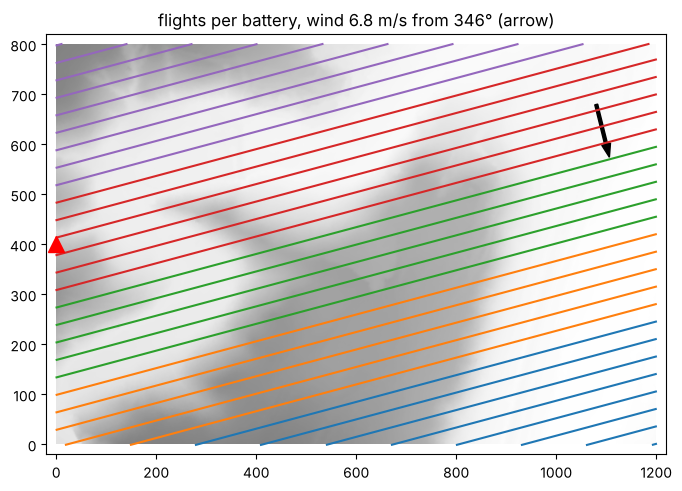

In [8]:
AZ = int(orient["time (min)"].idxmin())   # ◀ parameter: line azimuth (°); default is the fastest in the table
E_BAT, TEMP, RESERVE = 77.0, 1.0, 0.20     # ◀ parameter: battery (Wh), usable capacity (0.7–0.8 in frost), landing reserve
E_USE = E_BAT * TEMP * (1 - RESERVE)

def split(lines):
    """Split the lines into flights: add the next line only if energy for the return home remains after it."""
    flights, cur, e, pos = [], [], 0.0, HOME
    for a, b in lines:
        need = (leg_time(pos, a) + leg_time(a, b) + 2 * T_TURN) * P_AVG / 3600
        if cur and e + need + leg_time(b, HOME) * P_AVG / 3600 > E_USE:
            flights.append((cur, e + leg_time(pos, HOME) * P_AVG / 3600))
            cur, e, pos = [], 0.0, HOME
            need = (leg_time(pos, a) + leg_time(a, b) + 2 * T_TURN) * P_AVG / 3600
        cur.append((a, b)); e += need; pos = b
    flights.append((cur, e + leg_time(pos, HOME) * P_AVG / 3600))
    return flights

fl = split(plan(AZ))
print(f"azimuth {AZ}°, usable battery energy {E_USE:.1f} Wh: {len(fl)} flights")
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.imshow(dmr, cmap="Greys", extent=(0, W, 0, Hh), alpha=0.5)
for k, (lines, e) in enumerate(fl):
    col = plt.cm.tab10(k % 10)
    for a, b in lines:
        ax.plot([a[0], b[0]], [a[1], b[1]], color=col, lw=1.5)
    print(f"flight {k + 1}: {len(lines)} lines, {e:.1f} Wh")
ax.plot(*HOME, "r^", ms=12); ax.arrow(W - 120, Hh - 120, wvec[0] * 12, wvec[1] * 12, width=6, color="k")
ax.set(xlim=(-20, W + 20), ylim=(-20, Hh + 20), title=f"flights per battery, wind {WIND:.1f} m/s from {WDIR:.0f}° (arrow)"); plt.show()

> **✏️ Task 5.** How many flights does the mission need, and why do the flights have different numbers of lines? Move the take-off point `HOME` to the centre of the area (600, 400) and rerun the cells from the data loading: do you save a flight? Set `TEMP = 0.75` as in frost. Why does planning count on returning against the wind, even though the wind may weaken during the flight?

*Your answer:* 

> **✏️ Extension (optional).** Set `LON, LAT` to the slope above the Brno reservoir (16.4798, 49.2467) or the valley near Hosín by Hluboká nad Vltavou (14.4769, 49.0452), where the terrain also rises from east to west, and compare coverage, smoothing and number of flights with Roztoky.

*Your answer:* 

---
### Data sources and references

- Digital terrain model of the Czech Republic, 5th generation (DMR 5G) and digital surface model of the Czech Republic, 1st generation (DMP 1G), © ČÚZK, licence CC BY 4.0, services https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer and https://ags.cuzk.cz/arcgis2/rest/services/dmp1g/ImageServer
- ČÚZK: *Technical report on the digital surface model of the Czech Republic, 1st generation (DMP 1G)* (in Czech), https://geoportal.cuzk.gov.cz/Dokumenty/TECHNICKA_ZPRAVA_DMP_1G.pdf (total standard height error 0.4 m for buildings and 0.7 m for vegetation).
- Weather: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- DJI: *Mavic 3 Enterprise, specs* (https://enterprise.dji.com/mavic-3-enterprise/specs): 4/3 sensor, 5280 × 3956 px, 12.3 mm focal length; climb 6 m/s and descent 6 m/s in normal mode; 45 min endurance; 77 Wh battery.
- Flight height in the open category max. 120 m from the closest point of the surface of the earth: Commission Implementing Regulation (EU) 2019/947, Annex, UAS.OPEN.010.

### How to cite

OpenSkyLab (2026). Drone flight planner, advanced: image coverage, terrain following, wind and batteries [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/flight_planner_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*